> **Language & Quick Links**: [🇰🇷 Korean (`notebooks/ko/stage3_property_graph_bigquery_spanner_ko.ipynb`)](../ko/stage3_property_graph_bigquery_spanner_ko.ipynb) · **🇺🇸 English (Current Folder: `notebooks/en/`)** ｜ [Methodology Guide](../../methodology/en/03_stage3_property_graph_en.md) ｜ [Notebook Index (README)](../README.md) ｜ [Open Live Studio Tab](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage3)
>
> **Lifecycle Navigation**: [0. End-to-End Overview](./stage0_overview_walkthrough_en.ipynb) → [Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) → [Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb) → **[▶ Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb)** → [Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb) → [Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb)

---

# Stage 3. [Build Graph] Ready-to-Use Zero-ETL Physical Property Graph (BigQuery / Spanner) & Parameterized ISO GQL
## Step 3.1 6 Node × 4 Edge Metamodel Design & DDL Provisioning · Step 3.2 Instance Topology & Parameterized ISO GQL / NL2GQL

Stage 3 connects directly to the **Ready-to-Use Dual Property Graph** provisioned in **Phase 5 (Physical Property Graph Construction)**. Without duplicating data (**Zero-ETL**), the 10 BigQuery tables are projected into `STARTER_ONTOLOGY_GRAPH` with **6 Node Labels** and **4 Edge Labels**, verified via `stage3_resource_check`, and queried via multi-hop ISO GQL and Gemini NL-to-GQL (`nl2gql`).

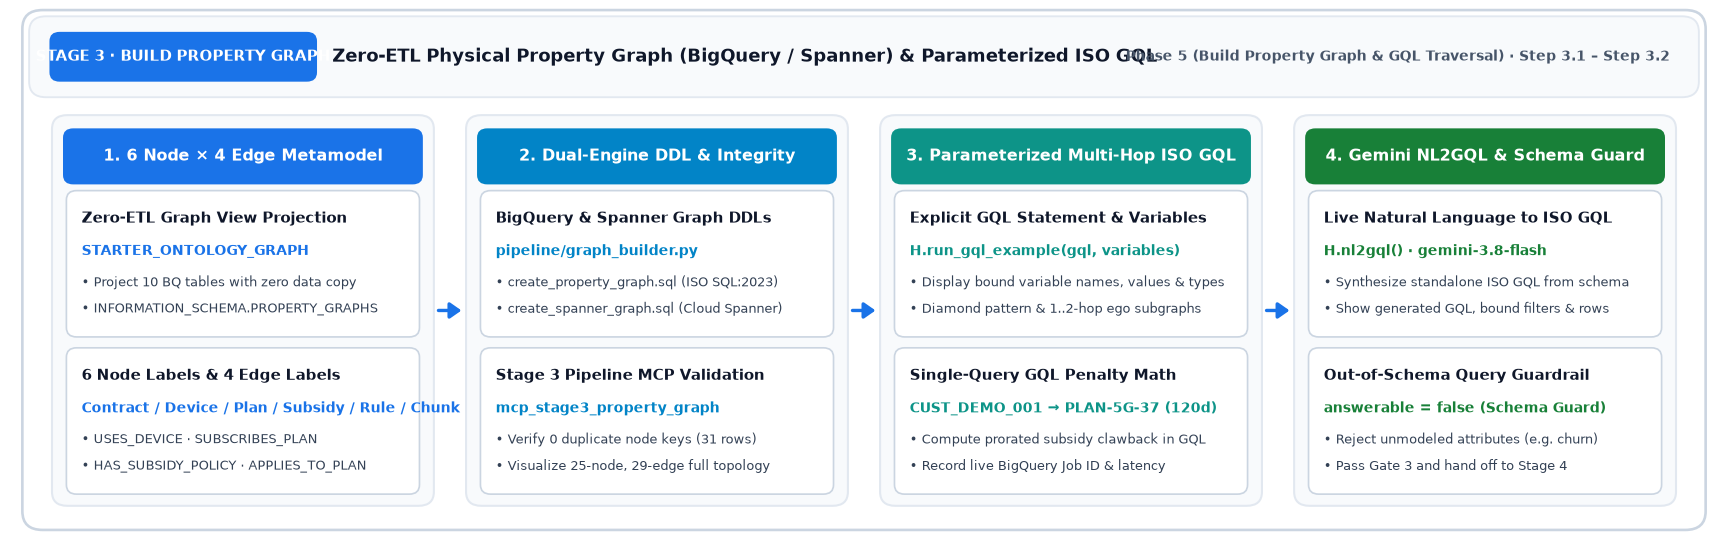


In [ ]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
H.setup("en")
server = DomainMcpServer()


### 1. [Phase 5a: Graph Schema Design & Metamodel] `INFORMATION_SCHEMA.PROPERTY_GRAPHS` Metadata & 6 Node × 4 Edge Metamodel Schematic


In [ ]:
node_labels, edge_labels, meta = H.graph_metadata()
H.md(f"**Live Property Graph Catalog Job**: `{meta['job_id']}` ({meta['elapsed_ms']} ms) · Nodes `{len(node_labels)}` · Edges `{len(edge_labels)}`")
H.show(pd.DataFrame(node_labels))
H.show(pd.DataFrame(edge_labels))
H.draw_property_graph_metamodel()


### 2. [Phase 5b: Dual-Engine DDL Provisioning & Integrity Check] BigQuery / Spanner Graph DDL & `stage3_resource_check` Execution


In [ ]:
H.show_md_file(H.ROOT / "data/output/create_property_graph.sql", max_lines=38)
H.show_md_file(H.ROOT / "data/output/create_spanner_graph.sql", max_lines=38)
res_s3 = server.execute_tool("stage3_resource_check", {"steps": ["promote_dw_nodes", "synthesize_graph_ddl", "verify_gql_templates"]})
H.show_tool(res_s3, "node_tables")
H.show(pd.DataFrame([res_s3["gql_paths"]]))


### 3. [Phase 5c: Instance Data & Topology Visualization] Node & Edge Label Distribution (`%%bqsql`) and Full Instance Topology


In [ ]:
%%bqsql df_gnodes
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (n)
RETURN LABELS(n)[OFFSET(0)] AS label, COUNT(*) AS nodes
GROUP BY label
ORDER BY nodes DESC


In [ ]:
%%bqsql df_gedges
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH ()-[e]->()
RETURN LABELS(e)[OFFSET(0)] AS label, COUNT(*) AS edges
GROUP BY label
ORDER BY edges DESC


In [ ]:
%%bqsql df_all_paths
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (a)-[e]->(b)
RETURN TO_JSON(p) AS path


In [ ]:
H.md(H._format_vars_md({
    "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "Target BigQuery Property Graph"),
    "pattern (n) / (a)-[e]->(b)": ("ALL_LABELS (6N × 4E)", "Full node/edge label scan & JSON path projection"),
}) + "**" + "Executed ISO GQL Statements" + "**\n```sql\n"
f"GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`\nMATCH p = (a)-[e]->(b)\nRETURN TO_JSON(p) AS path\n```")
H.show(df_gnodes)
H.show(df_gedges)
H.bar(df_gnodes, "label", "nodes", "Node Count by Label",
      color=[H.LABEL_COLORS.get(x, "#1A73E8") for x in H.pdf(df_gnodes)["label"]])
H.bar(df_gedges, "label", "edges", "Edge Count by Label", color="#0d9488")
nodes, edges = H.paths_to_graph(H.pdf(df_all_paths)["path"])
H.draw_graph(nodes, edges, "Full STARTER_ONTOLOGY_GRAPH Instance Topology (25 Nodes · 29 Edges · 5-Column Layout)", legend=H.LABEL_COLORS)


### 4. [Phase 5d: Parameterized Multi-Hop ISO GQL Patterns (`H.run_gql`)] Executed GQL Statements, Bound Variables, Result Tables & 1..2-Hop Ego Subgraph


In [ ]:
# GQL-01: 2-Hop Customer Contract -> Device & Subscribed Plan
gql_1 = """GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode),
      (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)
RETURN c.customer_id AS customer_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days,
       d.device_name AS device_name, p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw
ORDER BY customer_id"""
df_g1, _ = H.run_gql(
    gql_1,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "Property Graph view"),
        "edge_1": ("USES_DEVICE", "CustomerContractNode -> DeviceNode"),
        "edge_2": ("SUBSCRIBES_PLAN", "CustomerContractNode -> PlanNode"),
    },
    title="GQL-01 · 2-Hop Customer Contract to Device & Subscribed Plan",
)

# GQL-02: Diamond Pattern (Contract -> Device -> Subsidy -> Plan <- Contract)
gql_3 = """GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[:SUBSCRIBES_PLAN]-(c)
RETURN c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name,
       hs.total_subsidy_krw AS policy_total_subsidy_krw, c.granted_subsidy_krw AS granted_subsidy_krw
ORDER BY customer_id"""
df_g3, _ = H.run_gql(
    gql_3,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "Property Graph view"),
        "pattern": ("(c)-[:USES_DEVICE]->(d)-[hs:HAS_SUBSIDY_POLICY]->(p)<-[:SUBSCRIBES_PLAN]-(c)",
                    "4-node closed diamond consistency pattern"),
    },
    title="GQL-02 · Diamond Pattern Match (Granted Subsidy vs. Policy Total Subsidy)",
)


In [ ]:
# GQL-03: Plan-to-DomainRule & SHA-256 DocChunk Anchor Join
target_plan_for_rules = "PLAN-5G-37"
gql_6 = f"""GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (r:DomainRuleNode)-[a:APPLIES_TO_PLAN]->(p:PlanNode),
      (ch:DocChunkNode)
WHERE p.plan_id = '{target_plan_for_rules}' AND ch.chunk_id = a.source_chunk_id
RETURN r.rule_id AS rule_id, a.relation_label_ko AS relation_label_ko, p.plan_name AS plan_name,
       ch.chunk_id AS chunk_id, ch.section_title AS section_title, SUBSTR(ch.content, 1, 90) AS excerpt
ORDER BY rule_id"""
df_g6, _ = H.run_gql(
    gql_6,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "Property Graph view"),
        "$target_plan_id (p.plan_id)": (f"'{target_plan_for_rules}'", "PlanNode target plan_id filter"),
        "ch.chunk_id": ("a.source_chunk_id", "APPLIES_TO_PLAN edge to DocChunkNode join key"),
    },
    title="GQL-03 · Plan-Bound Domain Rules Joined with SHA-256 Policy Chunks",
)

# GQL-04: Single-Query Prorated Subsidy Clawback Calculation
cust_id_param = "CUST_DEMO_001"
target_plan_param = "PLAN-5G-37"
elapsed_days_param = 120
gql_8 = f"""GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode)-[cur:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[:SUBSCRIBES_PLAN]-(c),
      (d)-[tgt:HAS_SUBSIDY_POLICY]->(t:PlanNode),
      (s1:SubsidyNode), (s2:SubsidyNode)
WHERE c.customer_id = '{cust_id_param}' AND t.plan_id = '{target_plan_param}'
  AND s1.policy_id = cur.policy_id AND s2.policy_id = tgt.policy_id
RETURN c.customer_id AS customer_id, p.plan_name AS current_plan, t.plan_name AS target_plan,
       s1.base_subsidy_krw AS current_base_subsidy_krw, s2.base_subsidy_krw AS target_base_subsidy_krw,
       s1.mandatory_retention_days AS retention_days, {elapsed_days_param} AS elapsed_days,
       CAST(ROUND((s1.base_subsidy_krw - s2.base_subsidy_krw) * (s1.mandatory_retention_days - {elapsed_days_param}) / s1.mandatory_retention_days) AS INT64) AS penalty_krw"""
df_g8, _ = H.run_gql(
    gql_8,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "Property Graph view"),
        "$customer_id (c.customer_id)": (f"'{cust_id_param}'", "Target customer_id on CustomerContractNode"),
        "$target_plan_id (t.plan_id)": (f"'{target_plan_param}'", "Target downgrade plan_id on PlanNode"),
        "$elapsed_days": (str(elapsed_days_param), "Elapsed days since activation (prorated formula input)"),
    },
    title="GQL-04 · Single-Query ISO GQL Prorated Downgrade Penalty Calculation",
)


In [ ]:
# GQL-05: 1..2-Hop Variable-Length Ego Subgraph for CUST_DEMO_001
ego_customer = "CUST_DEMO_001"
gql_5 = f"""GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (c:CustomerContractNode)-[e]-{{1,2}}(n)
WHERE c.customer_id = '{ego_customer}'
RETURN LABELS(n)[OFFSET(0)] AS reached_label, PATH_LENGTH(p) AS hops, TO_JSON(p) AS path
ORDER BY hops, reached_label"""
df_g5, _ = H.run_gql(
    gql_5,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "Property Graph view"),
        "$customer_id (c.customer_id)": (f"'{ego_customer}'", "Center ego node customer_id"),
        "quantifier -{1,2}-": ("1..2 hops", "ISO GQL variable-length path quantifier"),
    },
    title="GQL-05 · 1..2-Hop Variable-Length Ego Subgraph Extraction for CUST_DEMO_001",
    show_df=False,
)
H.show(df_g5[["reached_label", "hops"]])
enodes, eedges = H.paths_to_graph(H.pdf(df_g5)["path"])
H.draw_graph(enodes, eedges, "CUST_DEMO_001 1..2-Hop Variable-Length Ego Subgraph (5-Column Layout)", legend=H.LABEL_COLORS)


### 5. [Phase 5e: Live Gemini NL-to-GQL (`nl2gql`) & Schema Guard] Natural Language to ISO GQL Statement, Bound Variables & Execution


In [ ]:
schema_str = H.schema_text(node_labels, edge_labels)
questions = [
    "List each customer contract with its device name, subscribed plan name, and monthly fee.",
    "For each plan, count the applied DomainRuleNodes and list their rule_ids ordered by monthly fee desc.",
    "Show base-station call quality complaints and churn scores per customer for August 2025.",
]
nl_rows = [H.nl2gql(q, schema_str) for q in questions]
H.show(pd.DataFrame(nl_rows))


### 6. [Phase 5f: Live Dual-Engine Latency Benchmark (p50/p95) & Graph Fabric (`EXTERNAL_QUERY`) Federated Join] BigQuery Property Graph (Default) vs. Cloud Spanner Graph (100 PU)


In [ ]:
df_bench = H.benchmark_dual_engine_df(runs=3)
H.show(df_bench)
H.grouped_bar(df_bench, "engine", ["p50_ms", "p95_ms"],
              "BigQuery Property Graph (Default) vs. Cloud Spanner Graph (100 PU) 3-Hop ISO GQL Latency (ms)",
              fmt="{:,.1f}", ylabel="Latency (ms)")


In [ ]:
_ = H.run_graph_fabric_federated_join()


### Q&A
- **Q.** How do Zero-ETL BigQuery Property Graph (default), Cloud Spanner Graph (low-latency option), and Graph Fabric (`EXTERNAL_QUERY`) complement each other?
  - **A.** `BigQuery Property Graph` (default) projects the 6 node and 4 edge tables with Zero-ETL for analytical and agent workloads, `Cloud Spanner Graph` (`100 PU`) serves low-latency online point traversals, and `EXTERNAL_QUERY(spanner_fabric_conn)` federates Spanner ISO GQL results directly with BigQuery `tb_doc_chunks` in a single query.

### Data Analysis Key Findings
- `STARTER_ONTOLOGY_GRAPH` comprises 6 node labels (31 rows, `0` duplicate keys) and 4 edge labels (31 rows), yielding 25 connected nodes and 29 directed edges.
- Using an ISO GQL diamond pattern (`GQL-04`) bound to `customer_id='CUST_DEMO_001'`, `target_plan_id='PLAN-5G-37'`, and `elapsed_days=120`, we computed the prorated downgrade penalty (`100,000 KRW`) in a single GQL query.
- Across 3 repeated runs, we benchmarked `p50`/`p95` traversal latency between BigQuery Property Graph (default) and Cloud Spanner Graph (`starter-spanner`, `100 PU`), and verified the `EXTERNAL_QUERY` federated join returning 10 rows across Spanner Graph and BigQuery `tb_doc_chunks`.

### Insights or Next Steps
- Proceed to `Stage 4 (Build Agent & Answer)` to see how the 3 Domain Business Tools (`DomainMcpServer`, `engine='bigquery' | 'spanner'`) and 2-Pass AI FDE (`Gate G2-W`) Agent orchestrate SQL and ISO GQL queries to generate grounded answers.

---
> **Next Navigation**: [⬅️ Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb) ｜ [🏠 0. Overview Home](./stage0_overview_walkthrough_en.ipynb) ｜ [➡️ Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb) ｜ [🌐 Korean Version](../ko/stage3_property_graph_bigquery_spanner_ko.ipynb) ｜ [📖 Methodology Doc](../../methodology/en/03_stage3_property_graph_en.md)
